# **Analisis Pendapatan Pos per Tahun 2024-2025**




blablabla

## 1. Penggunaan Library

Terdapat 3 library yang digunakan pada analisis kali ini, yaitu


*   **pandas**, berfungsi Membaca, membersihkan, mengolah, dan menganalisis dataset
*   **matplotlib.pyplot**, memiliki fungsi Membuat grafik pendapatan dan perbandingan
*   **seaborn**, supaya bisa membuat visualisasi seperti heatmap

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Membaca File

Membaca file transaksi pos periode tahun 2024-2025.

In [2]:
ds = pd.read_csv("/content/paket_a_transaksi_pos_2024_2025.csv")

In [3]:
print("Baris dan Kolom: ", ds.shape)

Baris dan Kolom:  (5030, 9)


In [4]:
print("List Kolom :")
print(ds.columns.tolist())

List Kolom :
['id_transaksi', 'tanggal', 'kode_gerai', 'kode_kasir', 'kode_produk', 'jumlah', 'harga_satuan', 'diskon_persen', 'status']


In [5]:
ds.head()

,id_transaksi,tanggal,kode_gerai,kode_kasir,kode_produk,jumlah,harga_satuan,diskon_persen,status
0,TRX0241065,2025-06-02,G09,K011,RMT1402,4,13000,0,SELESAI
1,TRX0240510,2024-12-28,G09,K015,SGR1205,1,21000,0,SELESAI
2,TRX0244483,2024-09-04,G11,K029,RMT1407,3,"7500,00",0,SELESAI
3,TRX0242532,2025-07-30,G05,K001,MKN1103,2,6500,0,SELESAI
4,TRX0243509,26/03/2025,G05,K016,RMT1407,1,6000,0,SELESAI


In [6]:
ds.tail()

,id_transaksi,tanggal,kode_gerai,kode_kasir,kode_produk,jumlah,harga_satuan,diskon_persen,status
5025,TRX0241722,2024-01-17,G01,K024,MIN1008,2,5500,0,SELESAI
5026,TRX0243698,2025-02-28,G01,K021,PRW1302,4,20500,0,SELESAI
5027,TRX0241377,2024-12-06,G08,K008,RMT1407,-1,7000,0,SELESAI
5028,TRX0241303,2025-10-01,G05,K008,MIN1003,-1,29000,15,SELESAI
5029,TRX0241752,2025-10-25,G03,K035,PRW1302,1,21000,0,SELESAI


In [7]:
ds.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5030 entries, 0 to 5029
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   id_transaksi   5030 non-null   object
 1   tanggal        5030 non-null   object
 2   kode_gerai     5030 non-null   object
 3   kode_kasir     4769 non-null   object
 4   kode_produk    5030 non-null   object
 5   jumlah         5030 non-null   int64 
 6   harga_satuan   5030 non-null   object
 7   diskon_persen  5030 non-null   int64 
 8   status         5030 non-null   object
dtypes: int64(2), object(7)
memory usage: 353.8+ KB


Berdasarkan hasil pemeriksaan data pada dataset, bisa diperoleh informasi jumlah data yang berjumlah 5030 dengan 9 kolom.

Adapun beberapa data yang perlu diperbaiki :

* Kolom `kode_kasir` memiliki 261 data kosong (missing value)
* Kolom `tanggal` masih bertipe object
* kolom `harga_satuan` bertipe object
* Terdapat data anomali yang bisa merusak analisis data



## 3. Explore & Cleaning Dataset

Menggunakan beberapa perintah untuk mencari masalah data seperti data rusak, hilang, atau tidak rapih lalu dilakukan cleaning (pembersihan) data.

### a. Missing Value

In [8]:
print(ds.isna().sum())

id_transaksi       0
tanggal            0
kode_gerai         0
kode_kasir       261
kode_produk        0
jumlah             0
harga_satuan       0
diskon_persen      0
status             0
dtype: int64


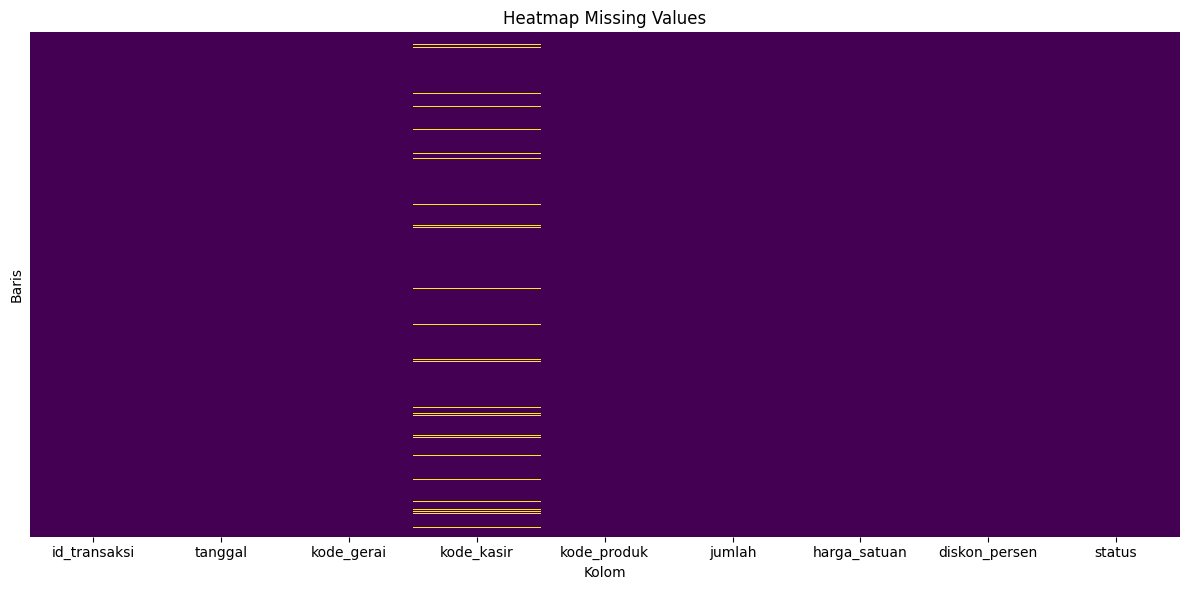

In [9]:
plt.figure(figsize=(12, 6))

sns.heatmap(
    ds.isna(),
    cbar=False,
    cmap="viridis",
    yticklabels=False
)

plt.title("Heatmap Missing Values")
plt.xlabel("Kolom")
plt.ylabel("Baris")
plt.tight_layout()
plt.show()

Terdapat missing value pada data `kode_kasir` sebanyak 261 data. Data yang kosong akan diisi dengan `TIDAK_DIKETAHUI`.





In [10]:
print("missing value:", ds['kode_kasir'].isnull().sum())

missing value: 261


In [11]:
ds['kode_kasir'] = ds['kode_kasir'].fillna(
    'TIDAK DIKETAHUI'
)

In [12]:
print("missing value:", ds['kode_kasir'].isnull().sum())

missing value: 0


### b. Data Duplikat

Mencari data duplikat yang ada di dalam dataset, lalu menghapus data yang duplikat tersebut.

In [13]:
print("Jumlah Data:", len(ds))

Jumlah Data: 5030


In [14]:
print("Jumlah duplikat:", ds.duplicated().sum())

Jumlah duplikat: 30


In [15]:
ds = ds.drop_duplicates()

In [16]:
print("Jumlah Data Setelah Pembersihan Duplikat:", len(ds))

Jumlah Data Setelah Pembersihan Duplikat: 5000


### c. Satuan Harga

Di dalam `harga_satuan` banyak format data yang kurang konsisten, ada yang ditulis pemisah berupa titik (.) dan koma (,).


Merapikan format harga agar semua data bisa dibaca dengan benar dan digunakan untuk menghitung pendapatan.

In [17]:
ds['harga_satuan'].head(10)

,harga_satuan
0,13000
1,21000
2,"7500,00"
3,6500
4,6000
5,45500
6,18000
7,47500
8,"11000,00"
9,6500


In [18]:
ds['harga_satuan'] = pd.to_numeric(
    ds['harga_satuan'].astype(str).str.replace(
        ',', '.', regex=False
    ),
    errors='coerce'
)

In [19]:
ds['harga_satuan'].head(10)

,harga_satuan
0,13000.0
1,21000.0
2,7500.0
3,6500.0
4,6000.0
5,45500.0
6,18000.0
7,47500.0
8,11000.0
9,6500.0


### d. Format Tanggal

Terdapat format tanggal yang tidak konsisten pada `tanggal`.

Dilakukan penyesuaian format agar seluruh tanggal menggunakan format tahun-bulan-hari (YYYY-MM-DD).

In [20]:
ds['tanggal'].head(10)

,tanggal
0,2025-06-02
1,2024-12-28
2,2024-09-04
3,2025-07-30
4,26/03/2025
5,2025-07-18
6,2025-09-24
7,2024-10-09
8,2024-03-20
9,2024-03-22


In [21]:
ds['tanggal'] = pd.to_datetime(
    ds['tanggal'],
    format='mixed',
    dayfirst=True,
    errors='coerce'
)

In [22]:
ds['tanggal'].head(10)

,tanggal
0,2025-06-02
1,2024-12-28
2,2024-09-04
3,2025-07-30
4,2025-03-26
5,2025-07-18
6,2025-09-24
7,2024-10-09
8,2024-03-20
9,2024-03-22


## 4. Data Anomali

Terdapat beberapa data anomali (abnormal) pada kolom jumlah yang dapat merusak hasil perhitungan pendapatan.

Data anomali yang dimaksud

* jumlah < 0 (jumlah barang negatif)

* jumlah > 100 (jumlah barang lebih dari 100)

In [23]:
print("Jumlah data < 0:", (ds['jumlah'] < 0).sum())
display(ds[ds['jumlah'] < 0])

Jumlah data < 0: 40


,id_transaksi,tanggal,kode_gerai,kode_kasir,kode_produk,jumlah,harga_satuan,diskon_persen,status
32,TRX0241782,2025-12-10,G04,K028,MIN1002,-6,45500.0,0,SELESAI
41,TRX0240181,2025-02-16,G07,K015,MKN1108,-12,9000.0,0,SELESAI
90,TRX0240898,2025-12-09,G05,K010,BYI1509,-3,46500.0,0,SELESAI
195,TRX0244719,2025-06-30,G03,K033,RMT1401,-1,10500.0,5,SELESAI
723,TRX0243147,2025-04-26,G09,TIDAK DIKETAHUI,MKN1106,-3,18500.0,0,SELESAI
847,TRX0241754,2025-02-06,G07,K017,BYI1502,-1,31000.0,10,BATAL
855,TRX0240649,2025-10-09,G12,K001,XXX9289,-2,13500.0,0,SELESAI
864,TRX0242385,2024-09-21,G08,K016,PRW1307,-2,9500.0,0,SELESAI
1054,TRX0243253,2025-04-30,G01,TIDAK DIKETAHUI,SGR1208,-1,33500.0,20,SELESAI
1495,TRX0241078,2024-07-28,G09,K002,MIN1005,-12,13500.0,10,RETUR


In [24]:
print("Jumlah data > 100:", (ds['jumlah'] > 100).sum())
display(ds[ds['jumlah'] > 100])

Jumlah data > 100: 12


,id_transaksi,tanggal,kode_gerai,kode_kasir,kode_produk,jumlah,harga_satuan,diskon_persen,status
87,TRX0243886,2025-12-27,G03,K040,PRW1306,2375,14500.0,0,SELESAI
244,TRX0243257,2024-11-24,G01,K033,MKN1102,1456,32500.0,20,SELESAI
467,TRX0243696,2024-02-27,G06,TIDAK DIKETAHUI,SGR1201,892,54000.0,0,SELESAI
660,TRX0242847,2025-02-24,G11,K007,RMT1404,661,13000.0,5,BATAL
926,TRX0240632,2024-09-08,G07,K026,RMT1403,1280,6500.0,0,SELESAI
994,TRX0241002,2024-03-18,G11,K038,MKN1101,2093,48000.0,10,SELESAI
1035,TRX0241068,2025-09-17,G09,K032,SGR1202,759,13.5,5,SELESAI
1323,TRX0240401,2025-02-02,G08,K029,MIN1009,641,11500.0,0,SELESAI
2414,TRX0241473,2024-12-08,G06,K037,PRW1308,1310,11000.0,0,SELESAI
3220,TRX0242632,2025-11-19,G10,K009,SGR1204,746,41500.0,0,SELESAI


In [25]:
total_anomali = (
    (ds['jumlah'] < 0).sum() +
    (ds['jumlah'] > 100).sum()
)

print("Total data anomali:", total_anomali)

Total data anomali: 52


Setelah data anomali diketahui, data tersebut dipisahkan dari data normal agar tidak memengaruhi hasil analisis selanjutnya.

In [26]:
ds = ds[
    (ds['jumlah'] >= 0) &
    (ds['jumlah'] <= 100)
].copy()

In [27]:
print("Data jumlah < 0:", (ds['jumlah'] < 0).sum())
print("Data jumlah > 100:", (ds['jumlah'] > 100).sum())

Data jumlah < 0: 0
Data jumlah > 100: 0


Data sudah bersih, bisa dilanjutkan menghitung pendapatan per tahun.

In [28]:
ds.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4948 entries, 0 to 5029
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   id_transaksi   4948 non-null   object        
 1   tanggal        4948 non-null   datetime64[ns]
 2   kode_gerai     4948 non-null   object        
 3   kode_kasir     4948 non-null   object        
 4   kode_produk    4948 non-null   object        
 5   jumlah         4948 non-null   int64         
 6   harga_satuan   4948 non-null   float64       
 7   diskon_persen  4948 non-null   int64         
 8   status         4948 non-null   object        
dtypes: datetime64[ns](1), float64(1), int64(2), object(5)
memory usage: 386.6+ KB


## 5. Menghitung Data Pendapatan

Dilakukan perhitungan pendapatan untuk mengetahui total pendapatan dari setiap transaksi

Pendapatan dihitung dari jumlah barang dikalikan dengan harga satuan, lalu dikurangi diskon jika tersedia.

Rumus yang digunakan :

`Pendapatan = Jumlah × Harga Satuan × (1 − Diskon / 100)`


In [29]:
ds['pendapatan'] = (
    ds['jumlah'] *
    ds['harga_satuan'] *
    (1 - ds['diskon_persen'] / 100)
)

In [30]:
display(
    ds[
        ['jumlah', 'harga_satuan', 'diskon_persen', 'pendapatan']
    ].head(10)
)

,jumlah,harga_satuan,diskon_persen,pendapatan
0,4,13000.0,0,52000.0
1,1,21000.0,0,21000.0
2,3,7500.0,0,22500.0
3,2,6500.0,0,13000.0
4,1,6000.0,0,6000.0
5,12,45500.0,10,491400.0
6,1,18000.0,0,18000.0
7,4,47500.0,10,171000.0
8,3,11000.0,0,33000.0
9,2,6500.0,0,13000.0


Memisahkan data transaksi berdasarkan tahun 2024 dan 2025.

In [31]:
ds['tahun'] = ds['tanggal'].dt.year

data_2024 = ds[ds['tahun'] == 2024].copy()
data_2025 = ds[ds['tahun'] == 2025].copy()

print("Jumlah data tahun 2024:", len(data_2024))
print("Jumlah data tahun 2025:", len(data_2025))

Jumlah data tahun 2024: 2468
Jumlah data tahun 2025: 2480


In [32]:
pendapatan_2024 = data_2024['pendapatan'].sum()
pendapatan_2025 = data_2025['pendapatan'].sum()

print(f"Total pendapatan tahun 2024: Rp {pendapatan_2024:,.0f}")
print(f"Total pendapatan tahun 2025: Rp {pendapatan_2025:,.0f}")

Total pendapatan tahun 2024: Rp 133,840,427
Total pendapatan tahun 2025: Rp 140,638,815


In [33]:
hasil = pd.DataFrame({
    'Tahun': [2024, 2025],
    'Jumlah Data': [len(data_2024), len(data_2025)],
    'Total Pendapatan': [
        pendapatan_2024,
        pendapatan_2025
    ]
})

display(hasil.style.format({
    'Total Pendapatan': 'Rp {:,.0f}'.format
}))

,Tahun,Jumlah Data,Total Pendapatan
0,2024,2468,"Rp 133,840,427"
1,2025,2480,"Rp 140,638,815"


## 5. Grafik

Grafik menunjukkan perbandingan total pendapatan pada tahun 2024 dan 2025 yang bertujuan untuk memudahkan pengamatan terhadap perbedaan pendapatan antara kedua tahun tersebut.

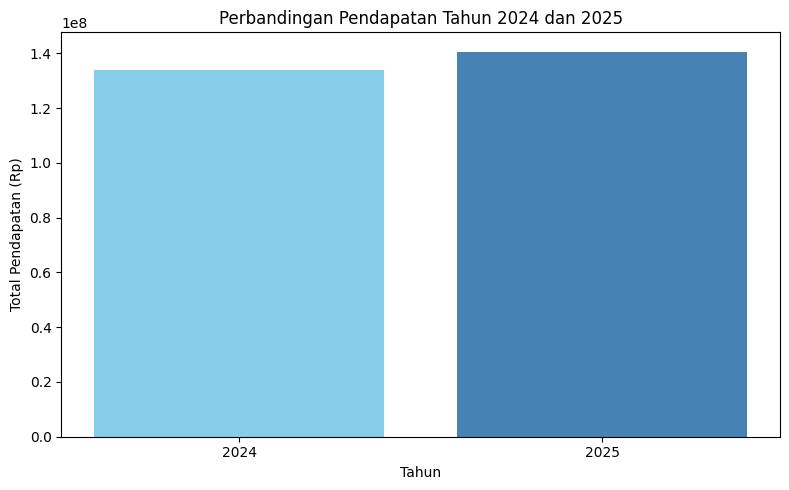

In [34]:
plt.figure(figsize=(8, 5))

plt.bar(
    hasil['Tahun'].astype(str),
    hasil['Total Pendapatan'],
    color=['skyblue', 'steelblue']
)

plt.title('Perbandingan Pendapatan Tahun 2024 dan 2025')
plt.xlabel('Tahun')
plt.ylabel('Total Pendapatan (Rp)')

plt.tight_layout()
plt.show()

## 6. Menyimpan Data

In [35]:
ds.to_csv('data_transaksi_bersih.csv', index=False)

In [36]:
ds['tanggal'] = pd.to_datetime(ds['tanggal'], dayfirst=True)
ds['tahun'] = ds['tanggal'].dt.year

In [37]:
data_2024.to_csv('data_transaksi_2024.csv', index=False)
data_2025.to_csv('data_transaksi_2025.csv', index=False)